# 03 · Frozen evaluation and error analysis

By default, this notebook displays development results and final-evaluation status. Once real human paraphrases and reviews are complete and all M0–M5 models have been trained, explicitly run `python -m src.evaluate freeze` in the terminal. The freeze records SHA-256 hashes of code, inputs, models, and variant files. Final evaluation becomes available only after this step.

Every model uses the same fixed class order, Macro-F1, accuracy, per-class precision/recall, and confusion matrices. Expression variation is compared on the same parent questions with complete original, paraphrase, and spelling versions.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "config.json").exists():
    ROOT = ROOT.parent
assert (ROOT / "config.json").exists(), "Open this notebook inside the project."
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import os
os.chdir(ROOT)
import pandas as pd


In [2]:
dev_metrics = pd.read_csv('results/dev/metrics.csv')
dev_metrics

,model_id,C,train_n,n,accuracy,macro_f1
0,M0,NaN,14158,1880,0.288830,0.074701
1,M1,NaN,14158,1880,0.989362,0.986207
2,M2,1.0,14158,1880,0.999468,0.999208
3,M3,0.1,14158,1880,0.999468,0.999208


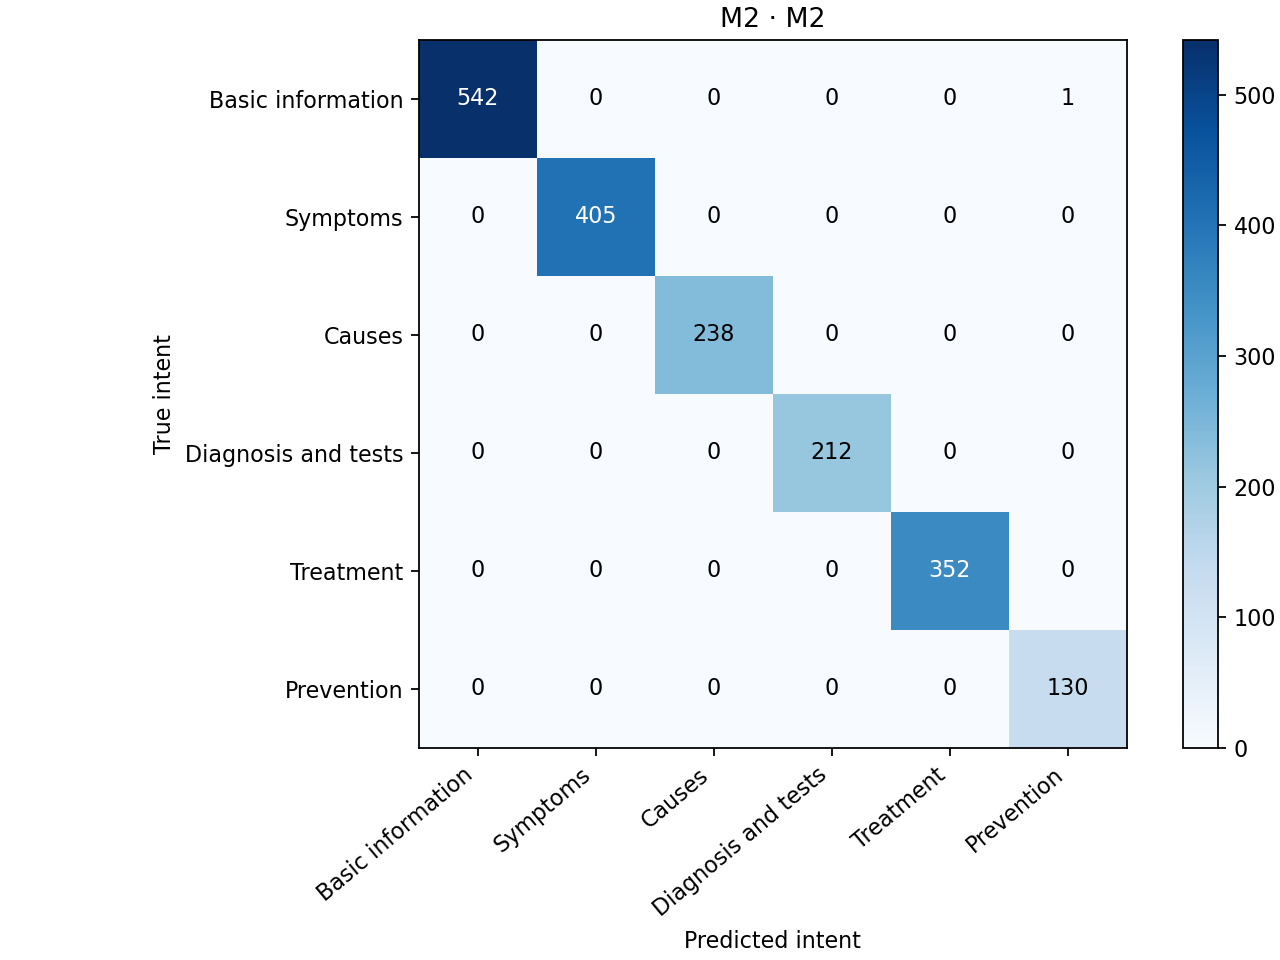

In [3]:
from IPython.display import Image, display
display(Image(filename='results/dev/M2_confusion.png'))

In [4]:
freeze_path = Path('results/final/freeze.json')
if freeze_path.exists():
    from src.evaluate import evaluate
    final_metrics = evaluate()
    display(final_metrics)
else:
    print('FINAL TEST NOT EVALUATED. Human paraphrases/reviews and protocol freeze are pending.')

FINAL TEST NOT EVALUATED. Human paraphrases/reviews and protocol freeze are pending.


## Development errors for inspection

The human analysis of final test errors will be saved in `results/final/error_analysis.csv`; that file has not yet been produced. The following cell displays actual development-set errors. If no errors exist, the table remains empty. These examples are part of development analysis.

In [5]:
from src.common import read_questions
pred = pd.read_csv('results/dev/predictions.csv')
errors = pred[(pred.model_id == 'M2') & (pred.label != pred.prediction)]
errors.merge(read_questions()[['question_id', 'question_text']], on='question_id')

,question_id,disease_group,label,model_id,prediction,question_text
0,10_MPlus_ADAM_QA/0002030.xml::0002030-1,how to prevent frostbite and hypothermia,Basic information,M2,Prevention,What is (are) How to prevent frostbite and hyp...
